In [1]:
# finds weird sensor values (humidity suddenly jumping, mic hitting its max) with an Isolation Forest
# our data has no labels for what's wrong and this model doesn't need any, then we compare it with simple threshold rules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
# raw file on purpose, the cleaned one already has the spikes smoothed out
# and in real time the model sees the raw values too, spikes included
df = pd.read_csv('data_final.csv')
df['pc_time'] = pd.to_datetime(df['pc_time'])
df = df.sort_values('pc_time').reset_index(drop=True)
print(df.shape)
df.describe()

(222452, 6)


,pc_time,uptime_ms,temp_c,humidity_pct,mic_peak
count,222452,2.224520e+05,222452.000000,222452.000000,2.224520e+05
mean,2026-11-08 10:12:25.996287,2.118804e+08,24.392117,70.523386,1.516659e+05
min,2026-11-05 20:24:54,2.265000e+03,18.800000,56.900000,0.000000e+00
25%,2026-11-07 03:18:40.500000,1.003898e+08,22.000000,66.600000,1.269810e+05
50%,2026-11-08 10:12:26,2.116153e+08,22.800000,67.900000,1.438360e+05
75%,2026-11-09 17:06:11.250000,3.228408e+08,27.100000,75.100000,1.633460e+05
max,2026-11-10 23:59:57,4.340663e+08,32.900000,88.500000,5.000000e+06
std,NaN,1.279953e+08,2.919579,5.186897,1.019803e+05


In [3]:
# a room can't really go up 5 %RH in 2 seconds, so big jumps from the previous row are suspicious
df['temp_jump'] = df['temp_c'].diff().abs().fillna(0)  # change from the previous row
df['hum_jump'] = df['humidity_pct'].diff().abs().fillna(0)
# log10 for the mic since it goes from thousands to millions
df['mic_log'] = np.log10(df['mic_peak'].clip(lower=1))

FEATURES = ['temp_c', 'humidity_pct', 'mic_log', 'temp_jump', 'hum_jump']
X = df[FEATURES]

In [4]:
# contamination is how many rows we expect to be anomalies, we guessed 0.5%
model = IsolationForest(n_estimators=100, contamination=0.005, random_state=42)
model.fit(X)
df['anomaly'] = (model.predict(X) == -1).astype(int)
df['score'] = -model.score_samples(X)   # higher score = more weird
print(df['anomaly'].sum(), 'rows flagged out of', len(df))

1113 rows flagged out of 222452


In [5]:
# the old way from Assignment 2 would just be thresholds: mic at max, humidity jumping over 3 %RH or temp over 0.5 °C in 2 seconds
df['rule_flag'] = (
    (df['mic_peak'] >= 5_000_000) |
    (df['hum_jump'] > 3) |
    (df['temp_jump'] > 0.5)
).astype(int)

print('Rule flags :', df['rule_flag'].sum())
print('Model flags:', df['anomaly'].sum())
print('Both       :', ((df['rule_flag'] == 1) & (df['anomaly'] == 1)).sum())
print()
# recall is how many of the rule problems the model also finds, the model flags way more rows than the rules
# not all of them are errors, some are just unusual combinations (like high humidity at a weird hour) that one threshold can't see
print('Using the rules as reference:')
print('  precision', round(precision_score(df['rule_flag'], df['anomaly']), 3))
print('  recall   ', round(recall_score(df['rule_flag'], df['anomaly']), 3))
print('  F1       ', round(f1_score(df['rule_flag'], df['anomaly']), 3))

Rule flags : 37
Model flags: 1113
Both       : 36

Using the rules as reference:
  precision 0.032
  recall    0.973
  F1        0.063


In [6]:
# the 15 weirdest rows
df.sort_values('score', ascending=False)[['pc_time', 'temp_c', 'humidity_pct', 'mic_peak', 'temp_jump', 'hum_jump', 'rule_flag']].head(15)

,pc_time,temp_c,humidity_pct,mic_peak,temp_jump,hum_jump,rule_flag
140022,2026-11-09 02:12:19,19.8,80.6,85021,2.0,13.8,1
62856,2026-11-07 07:20:07,20.5,82.3,116878,1.8,13.9,1
130150,2026-11-08 20:43:15,19.4,77.6,171722,3.5,11.7,1
79193,2026-11-07 16:24:41,32.7,66.1,112141,2.4,9.3,1
92234,2026-11-07 23:39:23,20.5,59.1,151237,2.1,6.9,1
23132,2026-11-06 09:16:00,28.3,88.3,217540,2.6,12.0,1
151738,2026-11-09 08:42:51,18.8,76.1,141780,2.6,8.9,1
93051,2026-11-08 00:06:37,20.5,56.9,145000,1.8,9.5,1
79194,2026-11-07 16:24:43,30.4,75.3,105852,2.3,9.2,1
172927,2026-11-09 20:29:09,27.9,76.2,1770379,0.2,0.7,0


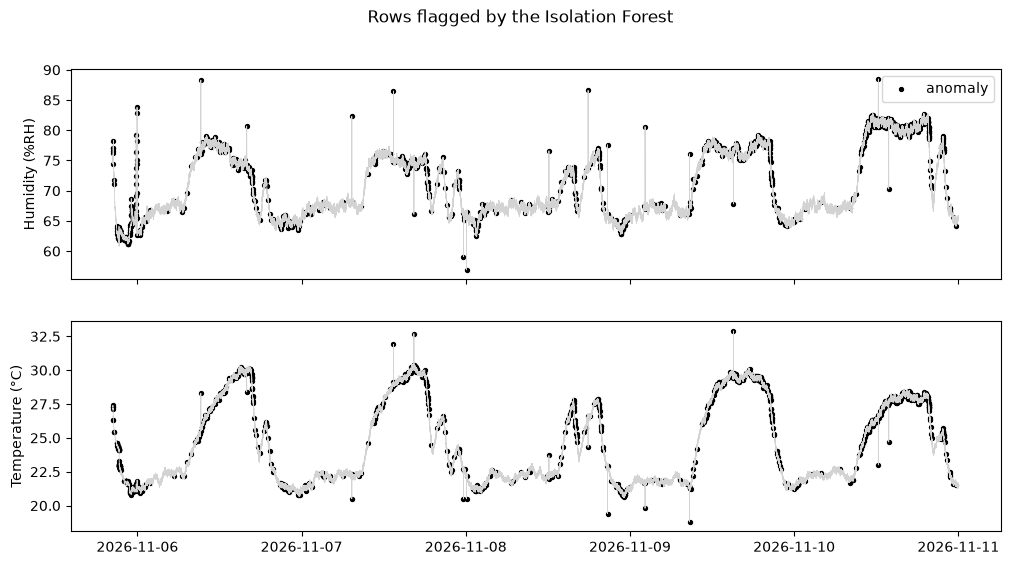

In [7]:
# humidity and temp over time with the flagged rows on top
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a = df[df['anomaly'] == 1]

ax[0].plot(df['pc_time'], df['humidity_pct'], color='lightgray', linewidth=0.6)
ax[0].scatter(a['pc_time'], a['humidity_pct'], color='black', s=8, label='anomaly')
ax[0].set_ylabel('Humidity (%RH)')
ax[0].legend()

ax[1].plot(df['pc_time'], df['temp_c'], color='lightgray', linewidth=0.6)
ax[1].scatter(a['pc_time'], a['temp_c'], color='black', s=8)
ax[1].set_ylabel('Temperature (°C)')

plt.suptitle('Rows flagged by the Isolation Forest')
plt.show()

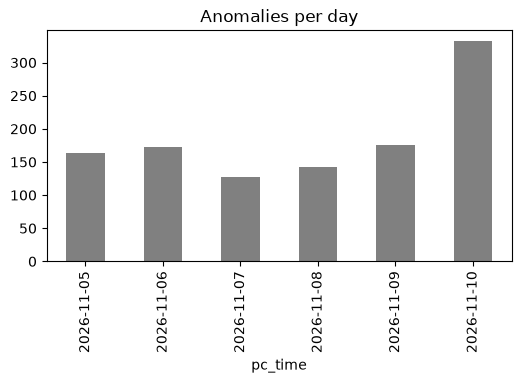

In [8]:
# how many got flagged each day
df.groupby(df['pc_time'].dt.date)['anomaly'].sum().plot(kind='bar', color='gray', figsize=(6, 3), title='Anomalies per day')
plt.show()

In [9]:
# save the model so service.py can load it without training again
# it checks every 2 second row from talos/readings against the previous one and sends the count per minute as anomalies, the board forwards it to ThingsBoard as pred_anomalies
joblib.dump({'model': model, 'features': FEATURES}, 'anomaly_model.pkl')
print('saved anomaly_model.pkl')

saved anomaly_model.pkl


In [10]:
# try it with one reading, humidity jumps from 64 to 82 in one step so it should get flagged
prev = {'temp_c': 25.0, 'humidity_pct': 64.0}
new = {'temp_c': 25.0, 'humidity_pct': 82.0, 'mic_peak': 40000}

row = pd.DataFrame([{
    'temp_c': new['temp_c'],
    'humidity_pct': new['humidity_pct'],
    'mic_log': np.log10(new['mic_peak']),
    'temp_jump': abs(new['temp_c'] - prev['temp_c']),
    'hum_jump': abs(new['humidity_pct'] - prev['humidity_pct']),
}])
print('Anomaly' if model.predict(row[FEATURES])[0] == -1 else 'Normal')

Anomaly
